In [ ]:
import sys, os
# make src/ importable when running from the notebooks/ folder
for _p in ('../src', 'src'):
    _ap = os.path.abspath(_p)
    if os.path.isdir(_ap) and _ap not in sys.path:
        sys.path.insert(0, _ap)


# Wind Energy Visualization: Offshore vs Onshore

## 1. Introduction to Wind Energy
In this analysis, we explore two types of wind energy generation:
- **Offshore Wind Energy**: Energy generated by wind turbines located at sea.
- **Onshore Wind Energy**: Energy generated by wind turbines located on land.



In [1]:
import pandas as pd

# Set pandas display options to show all rows and columns
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.width', None)  # Auto-detect the display width
pd.set_option('display.max_colwidth', None)  # Show full content of each column

# Function to load data from CSV
def load_data_from_csv(filename="../data/smard_data.csv"):
    return pd.read_csv(filename, index_col=0, parse_dates=True)

# Example usage
if __name__ == "__main__":
    data_df = load_data_from_csv()
    print(data_df)  # Display the entire DataFrame

                        1225      4067
timestamps                            
2015-01-04 23:00:00   473.75  11847.25
2015-01-05 00:00:00   464.75  11814.75
2015-01-05 01:00:00   461.50  12198.75
2015-01-05 02:00:00   450.25  12312.75
2015-01-05 03:00:00   453.50  13093.50
2015-01-05 04:00:00   458.25  14394.50
2015-01-05 05:00:00   430.25  14979.00
2015-01-05 06:00:00   396.25  14917.25
2015-01-05 07:00:00   335.50  14854.00
2015-01-05 08:00:00   322.75  14288.00
2015-01-05 09:00:00   332.00  13310.00
2015-01-05 10:00:00   356.50  11953.50
2015-01-05 11:00:00   411.25  10707.00
2015-01-05 12:00:00   386.75   9407.75
2015-01-05 13:00:00   319.50   7547.75
2015-01-05 14:00:00   273.50   5931.25
2015-01-05 15:00:00   196.00   4881.25
2015-01-05 16:00:00   154.75   4352.75
2015-01-05 17:00:00   157.00   4079.25
2015-01-05 18:00:00   217.00   3706.75
2015-01-05 19:00:00   172.00   3013.75
2015-01-05 20:00:00   157.00   2480.25
2015-01-05 21:00:00   173.75   1934.25
2015-01-05 22:00:00   191

# Monthly Wind Energy Generation: Offshore vs Onshore (2016 vs. 2024)

Index(['1225', '4067'], dtype='object')
                       1225      4067
timestamps                           
2015-01-04 23:00:00  473.75  11847.25
2015-01-05 00:00:00  464.75  11814.75
2015-01-05 01:00:00  461.50  12198.75
2015-01-05 02:00:00  450.25  12312.75
2015-01-05 03:00:00  453.50  13093.50


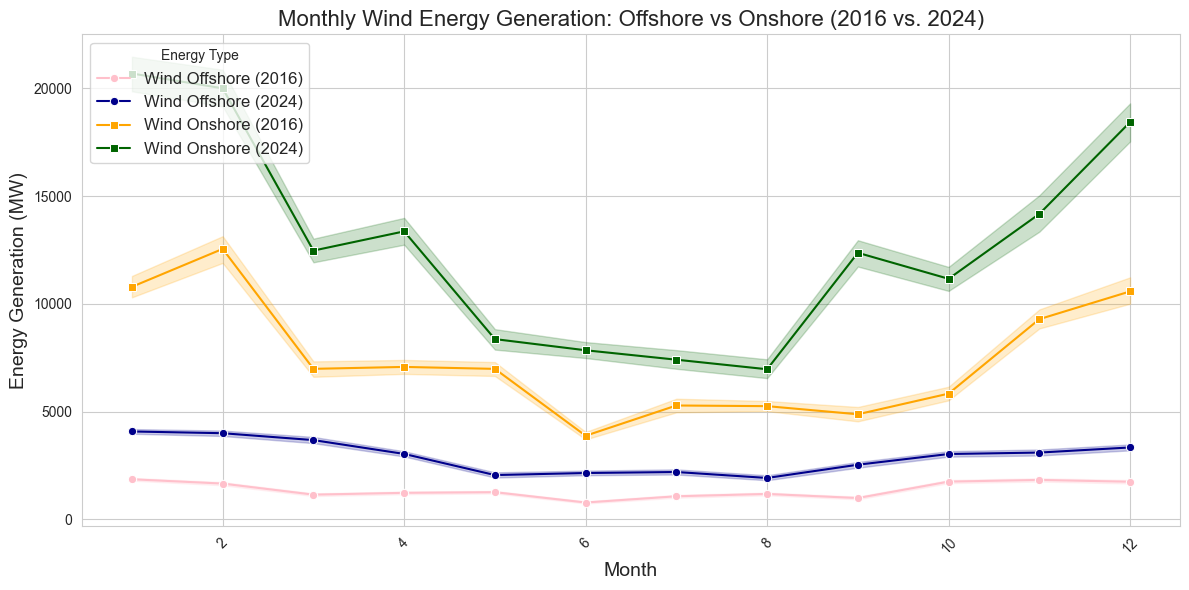

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv("../data/smard_data.csv", index_col=0, parse_dates=True)

# Check the columns and first few rows to ensure the correct structure
print(df.columns)
print(df.head())

# If 'Year' and 'Month' do not exist, create them
if 'Year' not in df.columns:
    df['Year'] = df.index.year

if 'Month' not in df.columns:
    df['Month'] = df.index.month

# Set style
sns.set_style("whitegrid")

# Create a line plot for 2016 and 2024 with clear labels
plt.figure(figsize=(12, 6))

# Plot for Wind Offshore (2016 and 2024)
sns.lineplot(data=df[df['Year'] == 2016], x="Month", y="1225", label="Wind Offshore (2016)", marker="o", color="pink")
sns.lineplot(data=df[df['Year'] == 2024], x="Month", y="1225", label="Wind Offshore (2024)", marker="o", color="darkblue")

# Plot for Wind Onshore (2016 and 2024)
sns.lineplot(data=df[df['Year'] == 2016], x="Month", y="4067", label="Wind Onshore (2016)", marker="s", color="orange")
sns.lineplot(data=df[df['Year'] == 2024], x="Month", y="4067", label="Wind Onshore (2024)", marker="s", color="darkgreen")

# Customize the plot
plt.title("Monthly Wind Energy Generation: Offshore vs Onshore (2016 vs. 2024)", fontsize=16)
plt.xlabel("Month", fontsize=14)
plt.ylabel("Energy Generation (MW)", fontsize=14)
plt.legend(title="Energy Type", loc="upper left", fontsize=12)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

# Display the plot
plt.tight_layout()  # Adjust layout to prevent overlapping
plt.show()






1)Wind energy fluctuates monthly due to changing weather patterns. Offshore wind is more stable, while onshore wind varies more.

2)Advances in wind technology may have increased efficiency. Comparing 2016 vs. 2024 helps assess improvements in power generation.

3)Higher wind energy in winter, lower in summer.

# Time Series Analysis of Wind Offshore and Wind Onshore Energy Generation: 30-Day Rolling Mean

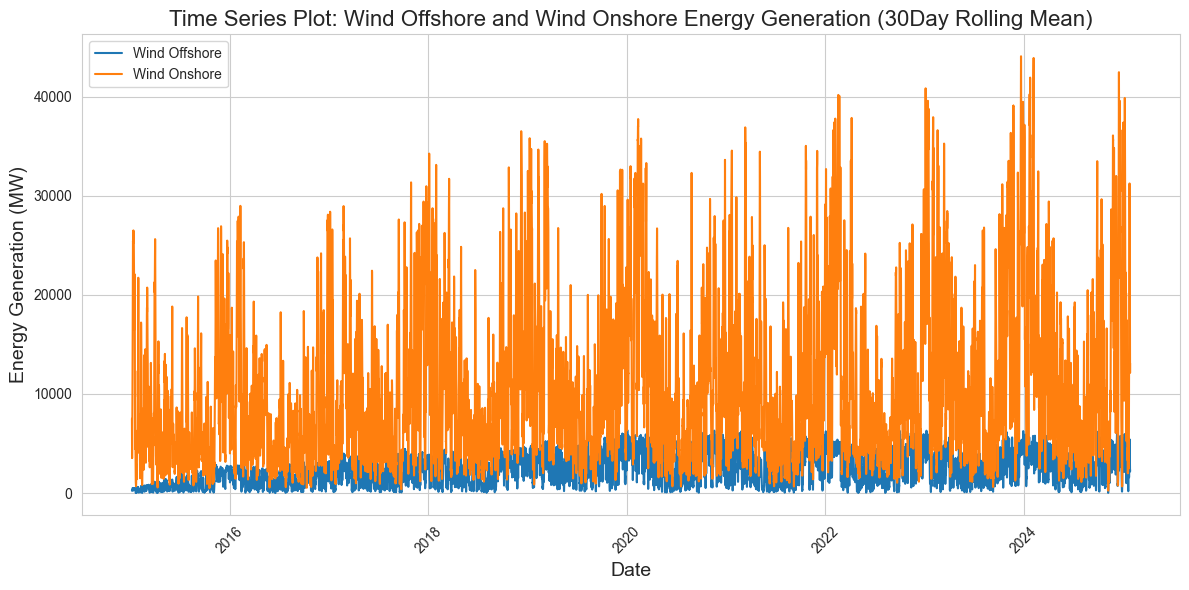

In [3]:
# Calculate rolling mean for smoothing
df_rolling = df.rolling(window=30).mean()

# Create a time series plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_rolling, x=df_rolling.index, y="1225", label="Wind Offshore")
sns.lineplot(data=df_rolling, x=df_rolling.index, y="4067", label="Wind Onshore")

# Add labels and title
plt.title("Time Series Plot: Wind Offshore and Wind Onshore Energy Generation (30Day Rolling Mean)", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Energy Generation (MW)", fontsize=14)
plt.legend(loc="upper left")

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

# Display the plot
plt.tight_layout()
plt.show()

1)Offshore wind (blue) generates less energy than onshore wind (orange) due to lower capacity and more stable output, as offshore turbines operate in more predictable conditions.

2)Onshore wind shows greater fluctuations, driven by weather, terrain, and intermittent wind patterns.

3)Both types show seasonal peaks, but onshore turbines experience higher volatility from local weather events.

# Distribution of Energy Generation: Offshore vs Onshore Wind Energy

                       1225      4067
timestamps                           
2015-01-04 23:00:00  473.75  11847.25
2015-01-05 00:00:00  464.75  11814.75
2015-01-05 01:00:00  461.50  12198.75
2015-01-05 02:00:00  450.25  12312.75
2015-01-05 03:00:00  453.50  13093.50


C:\Users\Sakshi Khodke\AppData\Local\Temp\ipykernel_14872\2825833008.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_melted, x="Source", y="Energy Generation", palette="Set2", split=True)


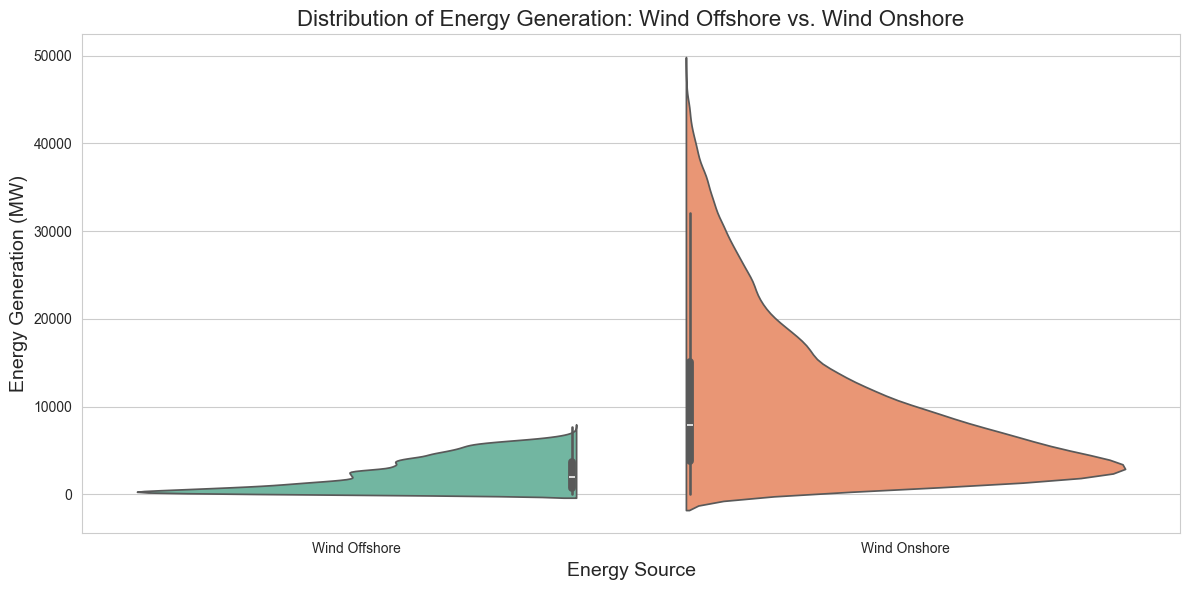

In [4]:
import pandas as pd

# Load the data
df = pd.read_csv("../data/smard_data.csv", index_col=0, parse_dates=True)
print(df.head())

# Reshape the data for Seaborn
df_melted = df.melt(value_vars=["1225", "4067"], var_name="Source", value_name="Energy Generation")

# Create a violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_melted, x="Source", y="Energy Generation", palette="Set2", split=True)

# Add labels and title
plt.title("Distribution of Energy Generation: Wind Offshore vs. Wind Onshore", fontsize=16)
plt.xlabel("Energy Source", fontsize=14)
plt.ylabel("Energy Generation (MW)", fontsize=14)
plt.xticks(ticks=[0, 1], labels=["Wind Offshore", "Wind Onshore"])

# Display the plot
plt.tight_layout()
plt.show()

The plot helps us understand the frequency and distribution of energy generation values over time for both offshore and onshore wind turbines.

1)For offshore wind, the distribution is narrower, indicating a more stable energy production profile. Onshore wind, on the other hand, has a broader distribution, showing greater variability in energy output.

2)The split violin allows for a side-by-side comparison, visually emphasizing the differences in the distribution of energy generation between the two sources.